In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuring display settings
plt.rcParams['figure.figsize'] = (12, 9)
sns.set()
sns.set_context('talk')
np.set_printoptions(threshold=20, precision=2, suppress=True)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)
pd.set_option('display.float_format', '{:.2f}'.format)
warnings.filterwarnings("ignore", category=FutureWarning)
import json

In [7]:
# Import config variable
with open("../../config.json") as f:
    cfg = json.load(f)
    
target = cfg["rc"]        
file_name = cfg["rc_file_name"]   
random_state = cfg["split"]["random_state"]  
# Load the dataset
data = pd.read_csv(f"../../data/{file_name}.csv")

In [8]:
from sklearn.model_selection import train_test_split 
X = data.drop(columns=[target])
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 118 samples
Test set size: 30 samples


{'max_depth': 5, 'max_features': 0.5, 'min_samples_leaf': 2, 'n_estimators': 200}
MAE (test): 0.17477042914376423
RMSE (test): 0.23213790779393634
R² (test): 0.9446313293519978
 
MAE (train): 0.16422452634628226
RMSE (train): 0.22336500187909228
R² (train): 0.950237965126444


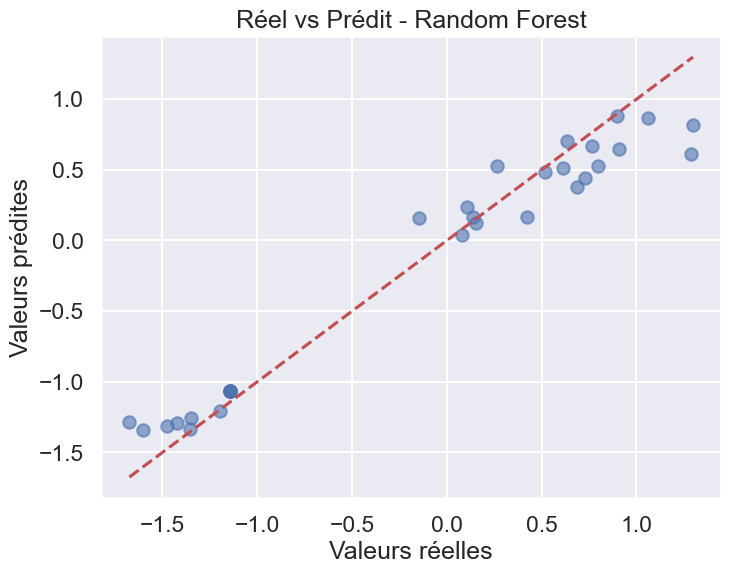

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np


from sklearn.model_selection import GridSearchCV
param_grid = {
    'n_estimators': [100, 200], # Nombre d'arbre de décision dans la forêt
    'max_depth': [4, 5], # profondeur de l'arbre
    'min_samples_leaf': [2, 4, 8], # nombre d'exemple  minimum pour effectuer un split
    'max_features': ['sqrt', 0.5], # Nombre de features que chaque arbre prend en compte à chaque split
}

grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)
print(grid_search.best_params_)

best_model = grid_search.best_estimator_
# Prédictions
y_pred = best_model.predict(X_test)

# Évaluation sur le test set
print("MAE (test):", mean_absolute_error(y_test, y_pred))
print("RMSE (test):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² (test):", r2_score(y_test, y_pred))
print(" ")

# Évaluation sur le train set
print("MAE (train):", mean_absolute_error(y_train, best_model.predict(X_train)))
print("RMSE (train):", np.sqrt(mean_squared_error(y_train, best_model.predict(X_train))))
print("R² (train):", r2_score(y_train, best_model.predict(X_train)))

# Visualisation réel vs prédit
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Réel vs Prédit - Random Forest')
plt.show()

<p>Le modèle généralise bien avec un R² entre test/train inférieur à 1% de différence, il est également bon avec 94% de la variance expliquée par le modèle. Les erreurs (MAE : 0.175, RMSE : 0.232) sont faibles et équilibrées entre entraînement et test, confirmant la stabilité du modèle. Comparé à XGBoost, le Random Forest offre une meilleure généralisation avec un overfitting minimal, rendant ce modèle plus fiable et robuste pour la production.</p>